In [1]:
import torch
import torch.nn as nn

from dataset import ALL_CLASSES, SpeechCommandsDatasetFactory
from model import Wav2Vec2KWS
from train import train, validate
from visualization import plot_loss, plot_metrics

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
model = Wav2Vec2KWS(num_classes=12).to(DEVICE)

In [4]:
print(model)

Wav2Vec2KWS(
  (feature_encoder): FeatureEncoder(
    (conv_layers): Sequential(
      (0): Conv1d(1, 512, kernel_size=(10,), stride=(5,), bias=False)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
      (3): LeakyReLU(negative_slope=0.01)
      (4): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
      (5): LeakyReLU(negative_slope=0.01)
      (6): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
      (7): LeakyReLU(negative_slope=0.01)
      (8): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
      (9): LeakyReLU(negative_slope=0.01)
      (10): Conv1d(512, 512, kernel_size=(2,), stride=(2,), bias=False)
      (11): LeakyReLU(negative_slope=0.01)
      (12): Conv1d(512, 512, kernel_size=(2,), stride=(2,), bias=False)
      (13): LeakyReLU(negative_slope=0.01)
    )
  )
  (feature_projection): FeatureProjection(
    (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)


In [5]:
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {num_params:,}")

Trainable parameters: 16,229,644


In [6]:
factory = SpeechCommandsDatasetFactory("train")

train_dataset = factory.train(skip_anomalies=True)
val_dataset = factory.val(skip_anomalies=True)
test_dataset = factory.test(skip_anomalies=True)

In [7]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)

In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

In [ ]:
epochs = 10

history = train(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    scheduler,
    DEVICE,
    epochs,
    "wav2vec.pt",
)


Epoch 1/10


train loss=1.4670 | train F1=0.4799 | train P=0.4807 | train R=0.4885
val   loss=0.7998 | val   F1=0.7495 | val   P=0.7511 | val   R=0.7525
Saved best model. val F1=0.7495

Epoch 2/10


train loss=0.5809 | train F1=0.8095 | train P=0.8092 | train R=0.8115
val   loss=0.4794 | val   F1=0.8474 | val   P=0.8527 | val   R=0.8492
Saved best model. val F1=0.8474

Epoch 3/10


train loss=0.3842 | train F1=0.8747 | train P=0.8744 | train R=0.8752
val   loss=0.4029 | val   F1=0.8656 | val   P=0.8713 | val   R=0.8661
Saved best model. val F1=0.8656

Epoch 4/10


train loss=0.2989 | train F1=0.9022 | train P=0.9021 | train R=0.9025
val   loss=0.3509 | val   F1=0.8910 | val   P=0.8947 | val   R=0.8909
Saved best model. val F1=0.8910

Epoch 5/10


...

train loss=0.1955 | train F1=0.9364 | train P=0.9363 | train R=0.9365
val   loss=0.3383 | val   F1=0.8958 | val   P=0.9020 | val   R=0.8960

Epoch 7/10


train loss=0.1524 | train F1=0.9506 | train P=0.9506 | train R=0.9507
val   loss=0.3086 | val   F1=0.9138 | val   P=0.9155 | val   R=0.9134
Saved best model. val F1=0.9138

Epoch 8/10


train loss=0.1329 | train F1=0.9575 | train P=0.9575 | train R=0.9576
val   loss=0.3439 | val   F1=0.9067 | val   P=0.9122 | val   R=0.9071

Epoch 9/10


train loss=0.1186 | train F1=0.9608 | train P=0.9608 | train R=0.9609
val   loss=0.3182 | val   F1=0.9139 | val   P=0.9159 | val   R=0.9140
Saved best model. val F1=0.9139

Epoch 10/10


train loss=0.0972 | train F1=0.9689 | train P=0.9688 | train R=0.9689
val   loss=0.3404 | val   F1=0.9155 | val   P=0.9178 | val   R=0.9154
Saved best model. val F1=0.9155


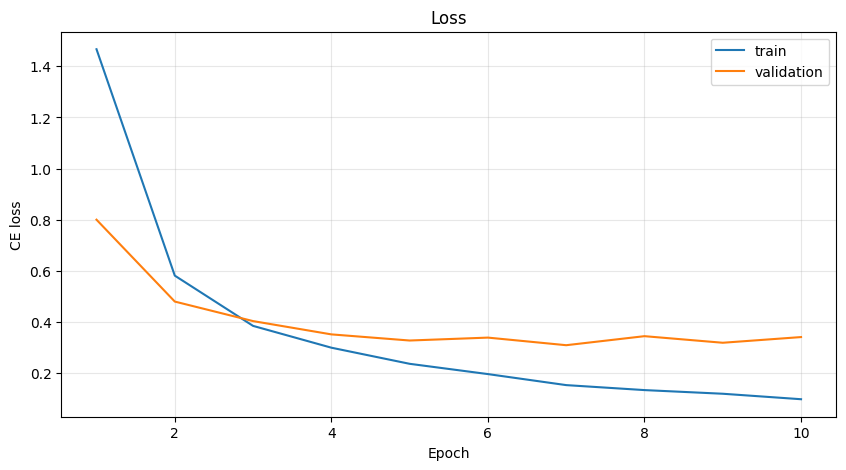

In [10]:
plot_loss(history)

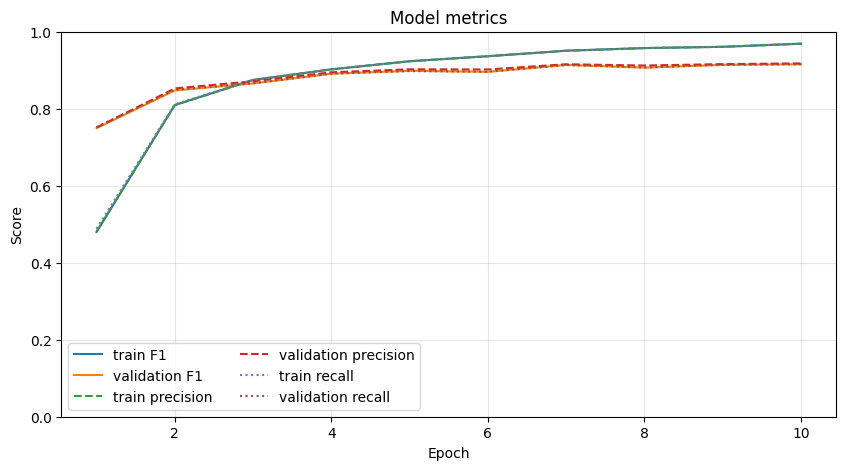

In [11]:
plot_metrics(history)

In [12]:
checkpoint = torch.load("wav2vec.pt", map_location="cpu")

model.load_state_dict(checkpoint["model_state_dict"])

model = model.to(DEVICE)

In [13]:
test_loss, test_metrics, test_true, test_pred = validate(
    model=model,
    loader=test_loader,
    criterion=criterion,
    device=DEVICE,
)

print(f"Test loss      : {test_loss:.4f}")

print(f"Test accuracy  : {test_metrics['accuracy']:.4f}")

print(f"Test precision : {test_metrics['precision']:.4f}")

print(f"Test recall    : {test_metrics['recall']:.4f}")

print(f"Test F1        : {test_metrics['f1']:.4f}")

Test loss      : 0.3589
Test accuracy  : 0.9145
Test precision : 0.9168
Test recall    : 0.9146
Test F1        : 0.9148


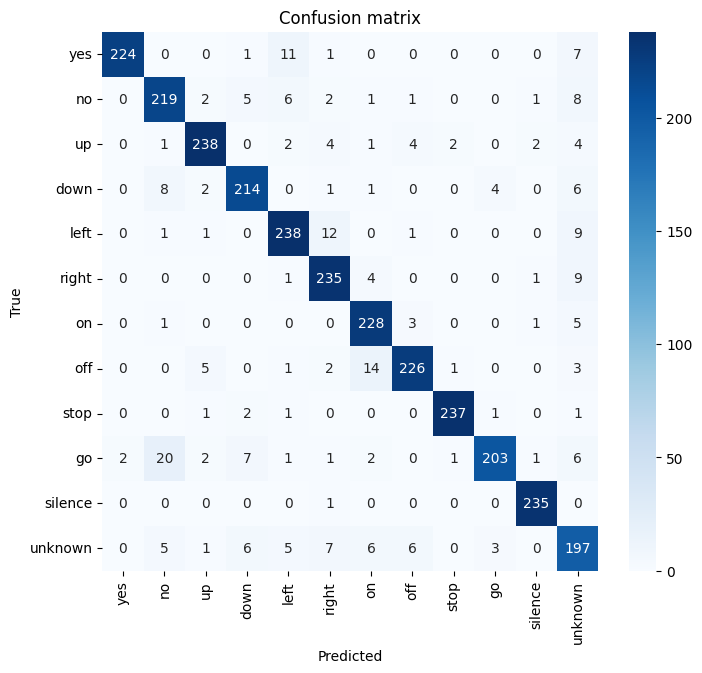

In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(test_true, test_pred)

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=ALL_CLASSES,
    yticklabels=ALL_CLASSES,
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix")
plt.show()